# Simulating the Amplitude-Based Collisionless QLBM

In [1]:
from qiskit_aer import AerSimulator

from qlbm.components import (
    ABGridMeasurement,
    EmptyPrimitive,
)
from qlbm.infra import QiskitRunner, SimulationConfig
from qlbm.lattice import ABLattice
from qlbm.tools.utils import create_directory_and_parents

In [2]:
lattice = ABLattice(
    {
        "lattice": {"dim": {"x": 16, "y": 16}, "velocities": "d2q9"},
        "geometry": [],
    }
)

output_dir = "qlbm-output/ab-pbc-d2q9-16x16-qiskit"
create_directory_and_parents(output_dir)

In [3]:
# Geometry of marker |0>: two "stacked" "wide" rectangles
# Geometry of the marker |1>: only the "top" rectangle is present
# These geometries will act fully in parallel, and we will observe the average behavior
lattice.set_geometries(
    [
        [
            {"shape": "cuboid", "x": [12, 14], "y": [6, 12], "boundary": "bounceback"},
            {"shape": "cuboid", "x": [3, 9], "y": [8, 10], "boundary": "bounceback"},
        ],
        [{"shape": "cuboid", "x": [6, 12], "y": [12, 14], "boundary": "bounceback"},],
    ]
)

In [22]:
lattice.geometries

[{'specular': [],
  'bounceback': [<qlbm.lattice.geometry.shapes.block.Block at 0x795e3a149590>,
   <qlbm.lattice.geometry.shapes.block.Block at 0x795e3a14bac0>]},
 {'specular': [],
  'bounceback': [<qlbm.lattice.geometry.shapes.block.Block at 0x795e67f46b50>]}]

In [23]:
from qlbm.components.ab.ab import ABQLBM
from qlbm.components.ab.initial import ABParallelDiscreteUniformInitialConditions

cfg = SimulationConfig(
    initial_conditions=ABParallelDiscreteUniformInitialConditions(
        lattice,
        [[5], [5]],
        [([0, 1], [0, 1, 2, 3]), ([0, 1], [0, 1, 2, 3])],
    ),
    algorithm=ABQLBM(lattice, use_agnostic_bcs=False),
    postprocessing=EmptyPrimitive(lattice),
    measurement=ABGridMeasurement(lattice),
    target_platform="QISKIT",
    compiler_platform="QISKIT",
    optimization_level=0,
    statevector_sampling=True,
    execution_backend=AerSimulator(method="statevector"),
    sampling_backend=AerSimulator(method="statevector"),
)

In [24]:
cfg.prepare_for_simulation()

In [25]:
# Number of shots to simulate for each timestep when running the circuit
NUM_SHOTS = 2**12

# Number of timesteps to simulate
NUM_STEPS = 40

In [26]:
runner = QiskitRunner(
    cfg,
    lattice,
)


# Simulate the circuits using both snapshots
runner.run(
    NUM_STEPS,  # Number of time steps
    NUM_SHOTS,  # Number of shots per time step
    output_dir,
    statevector_snapshots=True,
)

In [27]:
from pathlib import Path
print(Path(output_dir).resolve())

/home/aswa/Research/qlbm/demos/simulation/qlbm-output/ab-pbc-d2q9-16x16-qiskit


Saved 41 timesteps to /home/aswa/Research/qlbm/demos/simulation/qlbm-output/ab-pbc-d2q9-16x16-qiskit/simulation.gif


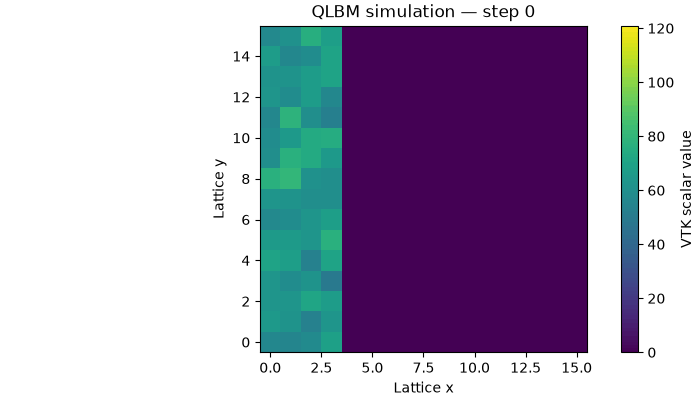

In [28]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
from matplotlib.animation import PillowWriter
from IPython.display import Image, display
from vtkmodules.vtkIOXML import vtkXMLImageDataReader
from vtkmodules.util.numpy_support import vtk_to_numpy

folder = Path(output_dir).resolve()
steps = []

for path in folder.rglob("step*.vti"):
    match = re.search(r"(\d+)$", path.stem)
    if match:
        steps.append((int(match.group(1)), path))

steps.sort()
if not steps:
    raise FileNotFoundError(f"No numbered step*.vti files found in {folder}")
if len({path.parent for _, path in steps}) > 1:
    raise ValueError("Multiple timestep folders found. Set folder to one run and retry.")

def read_frame(path):
    reader = vtkXMLImageDataReader()
    reader.SetFileName(str(path))
    reader.Update()
    grid = reader.GetOutput()
    nx, ny, nz = grid.GetDimensions()
    data = grid.GetPointData()
    scalars = data.GetScalars()
    if scalars is None and data.GetNumberOfArrays() == 1:
        scalars = data.GetArray(0)
    if nz != 1 or scalars is None or scalars.GetNumberOfComponents() != 1:
        raise ValueError(f"Expected a 2D scalar field in {path.name}")
    return vtk_to_numpy(scalars).reshape(ny, nx).copy()

frames = [read_frame(path) for _, path in steps]
low = min(frame.min() for frame in frames)
high = max(frame.max() for frame in frames)

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
plot = ax.imshow(frames[0], origin="lower", interpolation="nearest",
                 cmap="viridis", vmin=low, vmax=high)
fig.colorbar(plot, ax=ax, label="VTK scalar value")
ax.set(xlabel="Lattice x", ylabel="Lattice y")

gif_path = folder / "simulation.gif"
writer = PillowWriter(fps=5)
with writer.saving(fig, str(gif_path), dpi=100):
    for (step, _), frame in zip(steps, frames):
        plot.set_data(frame)
        ax.set_title(f"QLBM simulation — step {step}")
        writer.grab_frame()

plt.close(fig)
print(f"Saved {len(frames)} timesteps to {gif_path}")
display(Image(filename=str(gif_path)))